# Michiel's Library: Observed vs Predicted (KL)

In [1]:
using DrWatson
@quickactivate "Congrego"
using Congrego
using Plots
using CSV, DataFrames

# TODO - To run, download the data from https://github.com/lebedys/mscr-data-analysis
analysis_dir = projectdir("..", "dev")
# genotypes of the circuits we assembled
genotype_csv = joinpath(analysis_dir, "seq", "out", "michiel_lib_genotype_filtered.csv")
# observed phenotype per circuit
classify_csv = joinpath(analysis_dir, "nb", "out", "analyse_pr_classify.csv");

## Assembled Circuits

In [2]:
# The sequencing vocabulary is not the part catalogue's
rename = Dict(:Spacer1 => :LmrA, :Spacer2 => :tfSp, :Spacer3 => :BetI,
              :tPhIF => :TPhIF, :tSrpR => :TSrpR,
              # the sequencing data spells PhlF; this catalogue keeps PhIF
              :PhlF => :PhIF, :tPhlF => :TPhIF)

parts_of(genotype) = Symbol[get(rename, Symbol(p), Symbol(p)) for p in split(genotype, "-")]

genotypes = CSV.read(genotype_csv, DataFrame)
valid_assemblies = genotypes[genotypes.valid, :]
# one row per genotype: four genotypes reached two barcodes each, and both barcodes of
# every pair carry the same observed call
assembled = unique(valid_assemblies, :genotype)

println("$(nrow(valid_assemblies)) valid assemblies of $(nrow(genotypes)) filtered, "
        * "$(nrow(assembled)) unique genotypes")

58 valid assemblies of 68 filtered, 54 unique genotypes


## Observed Phenotypes

In [3]:
classified = CSV.read(classify_csv, DataFrame)
observed_function = Dict(zip(classified.Group, classified.logical_function_kl))

# circuit_25 in the genotype table, Circuit 25 in the classification
group_of(circuit) = "Circuit " * split(circuit, "_")[2]

labels = [pheno_labels(2); :invalid]
observed = [get(observed_function, group_of(circuit), missing) for circuit in assembled.circuit]

observed_counts = zeros(Int, length(labels))
for call in skipmissing(observed)
    observed_counts[findfirst(==(Symbol(call)), labels)] += 1
end

n_observed = sum(observed_counts)
println("$n_observed classified, $(observed_counts[end]) of them invalid, "
        * "$(count(ismissing, observed)) excluded by the classifier")

54 classified, 5 of them invalid, 0 excluded by the classifier


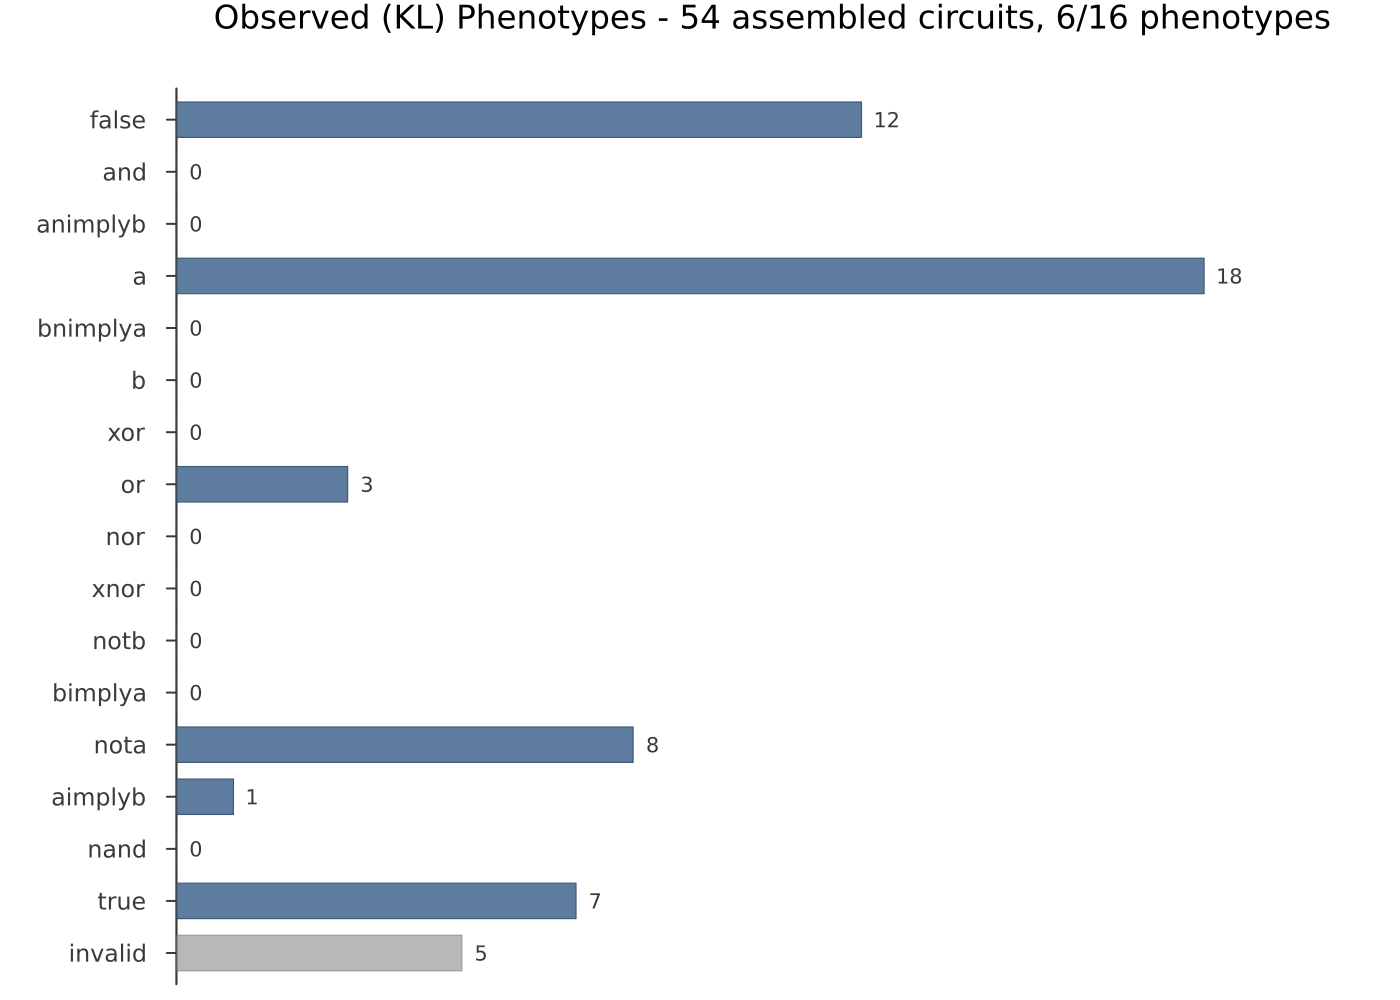

In [4]:
plot_phenotypes(labels, observed_counts;
    title="Observed (KL) Phenotypes - $n_observed assembled circuits, "
          * "$(count(>(0), observed_counts[1:end-1]))/16 phenotypes")

## Predicted Phenotypes

In [5]:
include(scriptsdir("parts", "ms_disable_Tra.jl"))
pc_tra = PC.pc
include(scriptsdir("parts", "ms_disable_Tra_roadblock_pTac.jl"))
pc_tra_rb = PC.pc

function predict(parts, pc)
    output, _ = simulate(Circuit(parts), pc.inputs; pc)
    any(ismissing, output) ? :invalid : pheno_label(Bool.(output))
end

results = DataFrame(
    circuit = assembled.circuit,
    circuit_parts = assembled.circuit_parts,
    observed = observed,
    predicted_disable_Tra = [predict(parts_of(g), pc_tra) for g in assembled.circuit_parts],
    predicted_disable_Tra_roadblock_pTac =
        [predict(parts_of(g), pc_tra_rb) for g in assembled.circuit_parts],
)

results

Row,circuit,circuit_parts,observed,predicted_disable_Tra,predicted_disable_Tra_roadblock_pTac
,String15,String,String7,Symbol,Symbol
1,circuit_25,pTac-SrpR-Spacer3-BM3R1-pTac-SrpR-Spacer3-BM3R1,a,a,a
2,circuit_37,AraC-PhlF-pSrpR-pTra-pBAD-Spacer1-pTac-SrpR-pSrpR-pTra-pBAD-Spacer2,nota,invalid,nota
3,circuit_49,pTac-SrpR-pSrpR-pTra-pBAD-Spacer2-AraC-PhlF-pSrpR-pTra-pBAD-BM3R1,false,nota,nota
4,circuit_85,pTac-SrpR-pTet-pTac-tSrpR-BM3R1-BM3R1-pTac-SrpR-pSrpR-pTra-Spacer1,nota,invalid,nota
5,circuit_2,AraC-PhlF-pSrpR-pTra-Spacer2-pTac-SrpR-pSrpR-pTra-BM3R1,aimplyb,invalid,nota
6,circuit_14,AraC-PhlF-pSrpR-pTra-pBAD-Spacer1-pTac-SrpR-Spacer3-BM3R1,a,invalid,a
7,circuit_38,AraC-PhlF-pSrpR-pTra-Spacer1-pTac-SrpR-Spacer3-BM3R1,a,invalid,a
8,circuit_74,pTac-SrpR-pTet-pTac-tSrpR-BM3R1-BM3R1-AraC-PhlF-Spacer3-TraRW,false,bnimplya,false
9,circuit_3,AraC-PhlF-Spacer3-TraRW-pTac-SrpR-Spacer3-BM3R1,a,a,a


## Observed vs Predicted

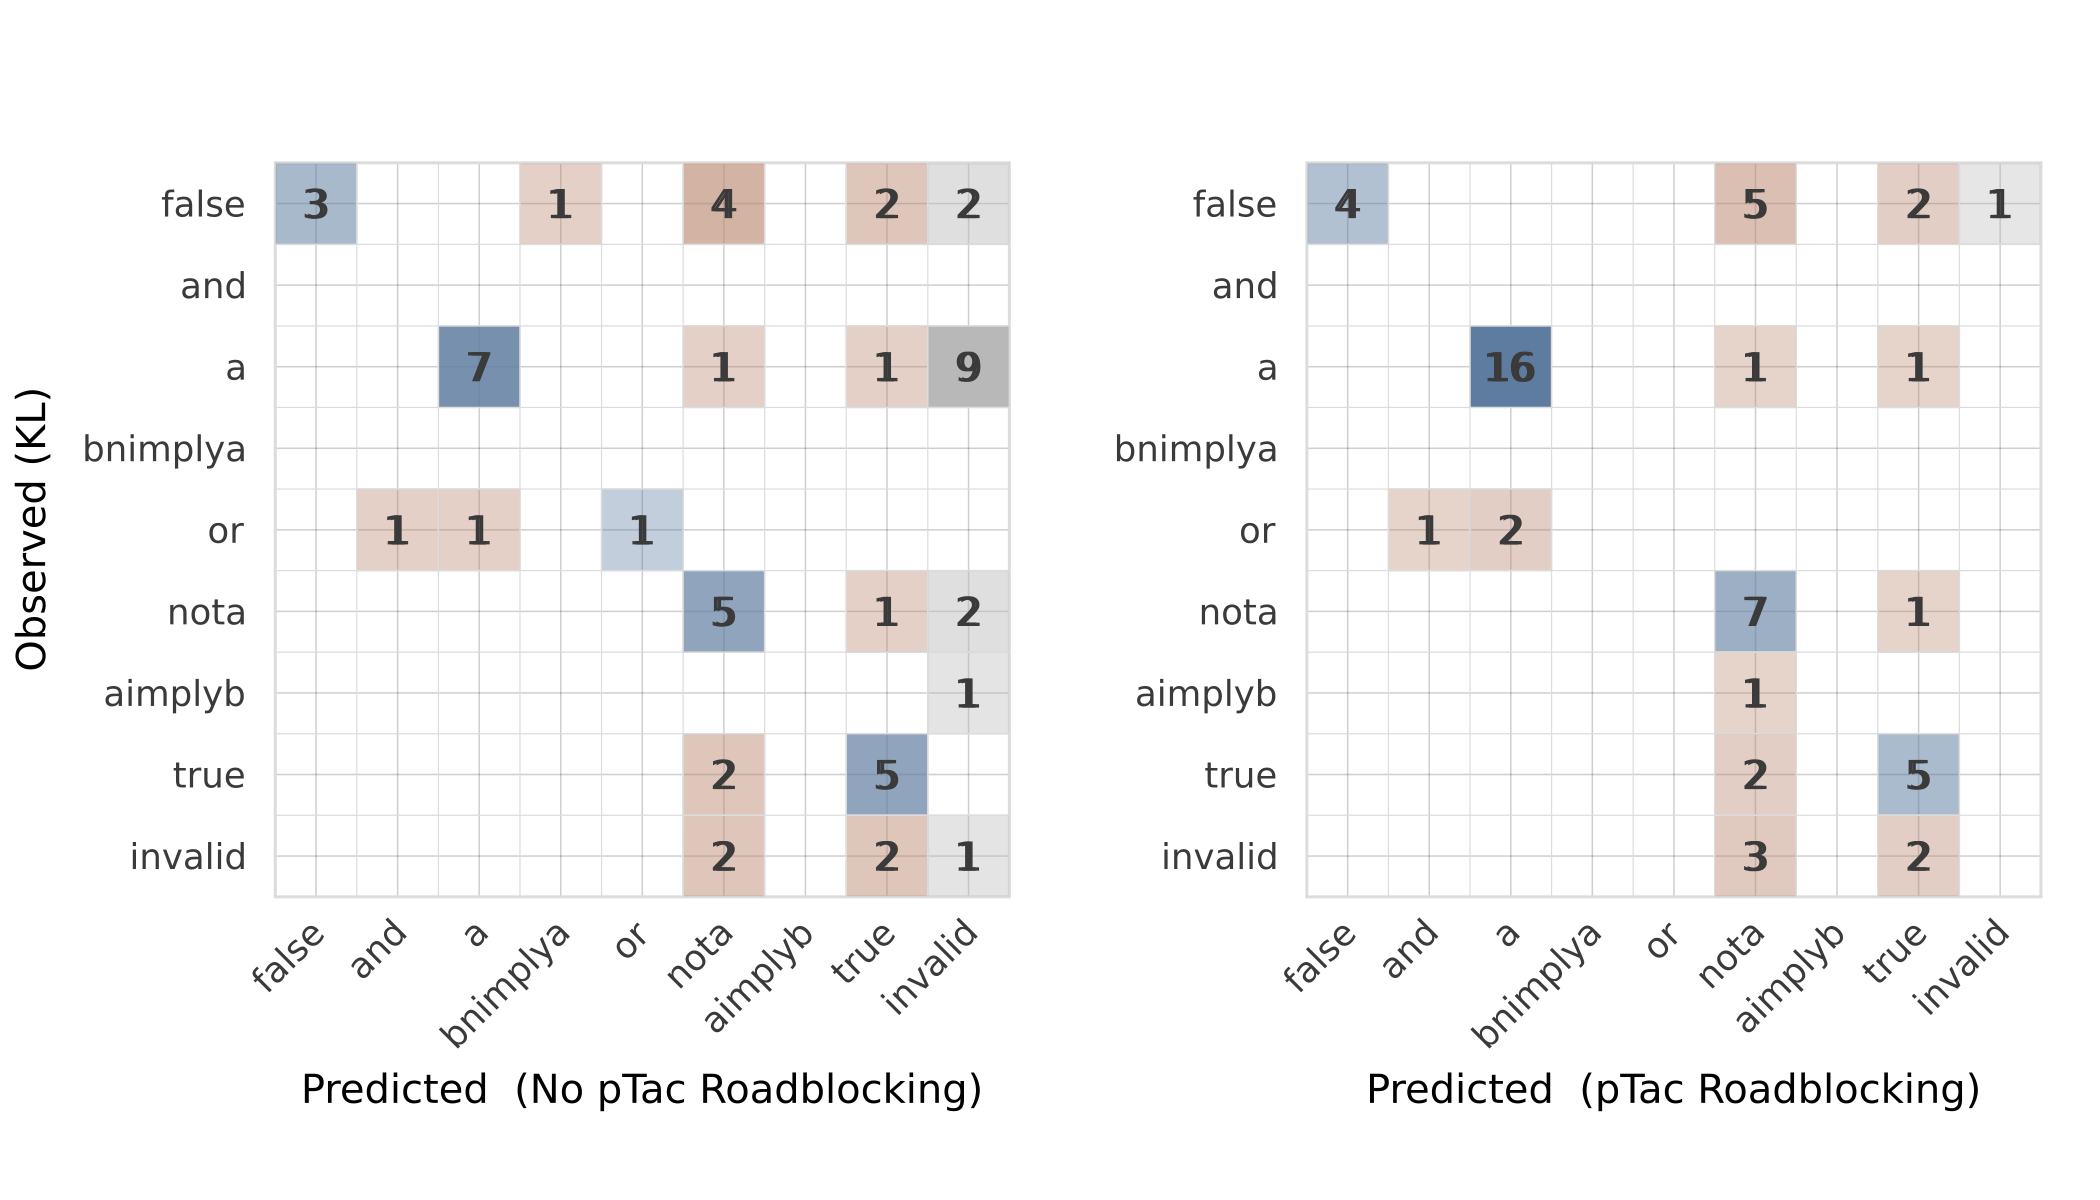

In [6]:
include(projectdir("notebooks", "confusion_matrix.jl"))

predictions = [results.predicted_disable_Tra, results.predicted_disable_Tra_roadblock_pTac]
confusion = confusion_labels(results.observed, predictions)
matrices = [confusion_counts(results.observed, prediction, confusion)
            for prediction in predictions]

# Landscape figure: two 10x10 grids need more than the 160 mm \textwidth to stay legible
figure_width_pt = 700
panel = (tickfontsize=8, guidefontsize=9,
         left_margin=2Plots.mm, right_margin=3Plots.mm,
         top_margin=2Plots.mm, bottom_margin=2Plots.mm)

fig = plot(
    confusion_panel(matrices[1], confusion; ylabel="Observed (KL)",
                    xlabel="Predicted  (No pTac Roadblocking)", panel...),
    confusion_panel(matrices[2], confusion; ylabel="",
                    xlabel="Predicted  (pTac Roadblocking)", panel...);
    layout=(1, 2), size=(figure_width_pt, 400), dpi=300)

savefig(fig, plotsdir("ms_experimental_confusion_kl.png"))
fig

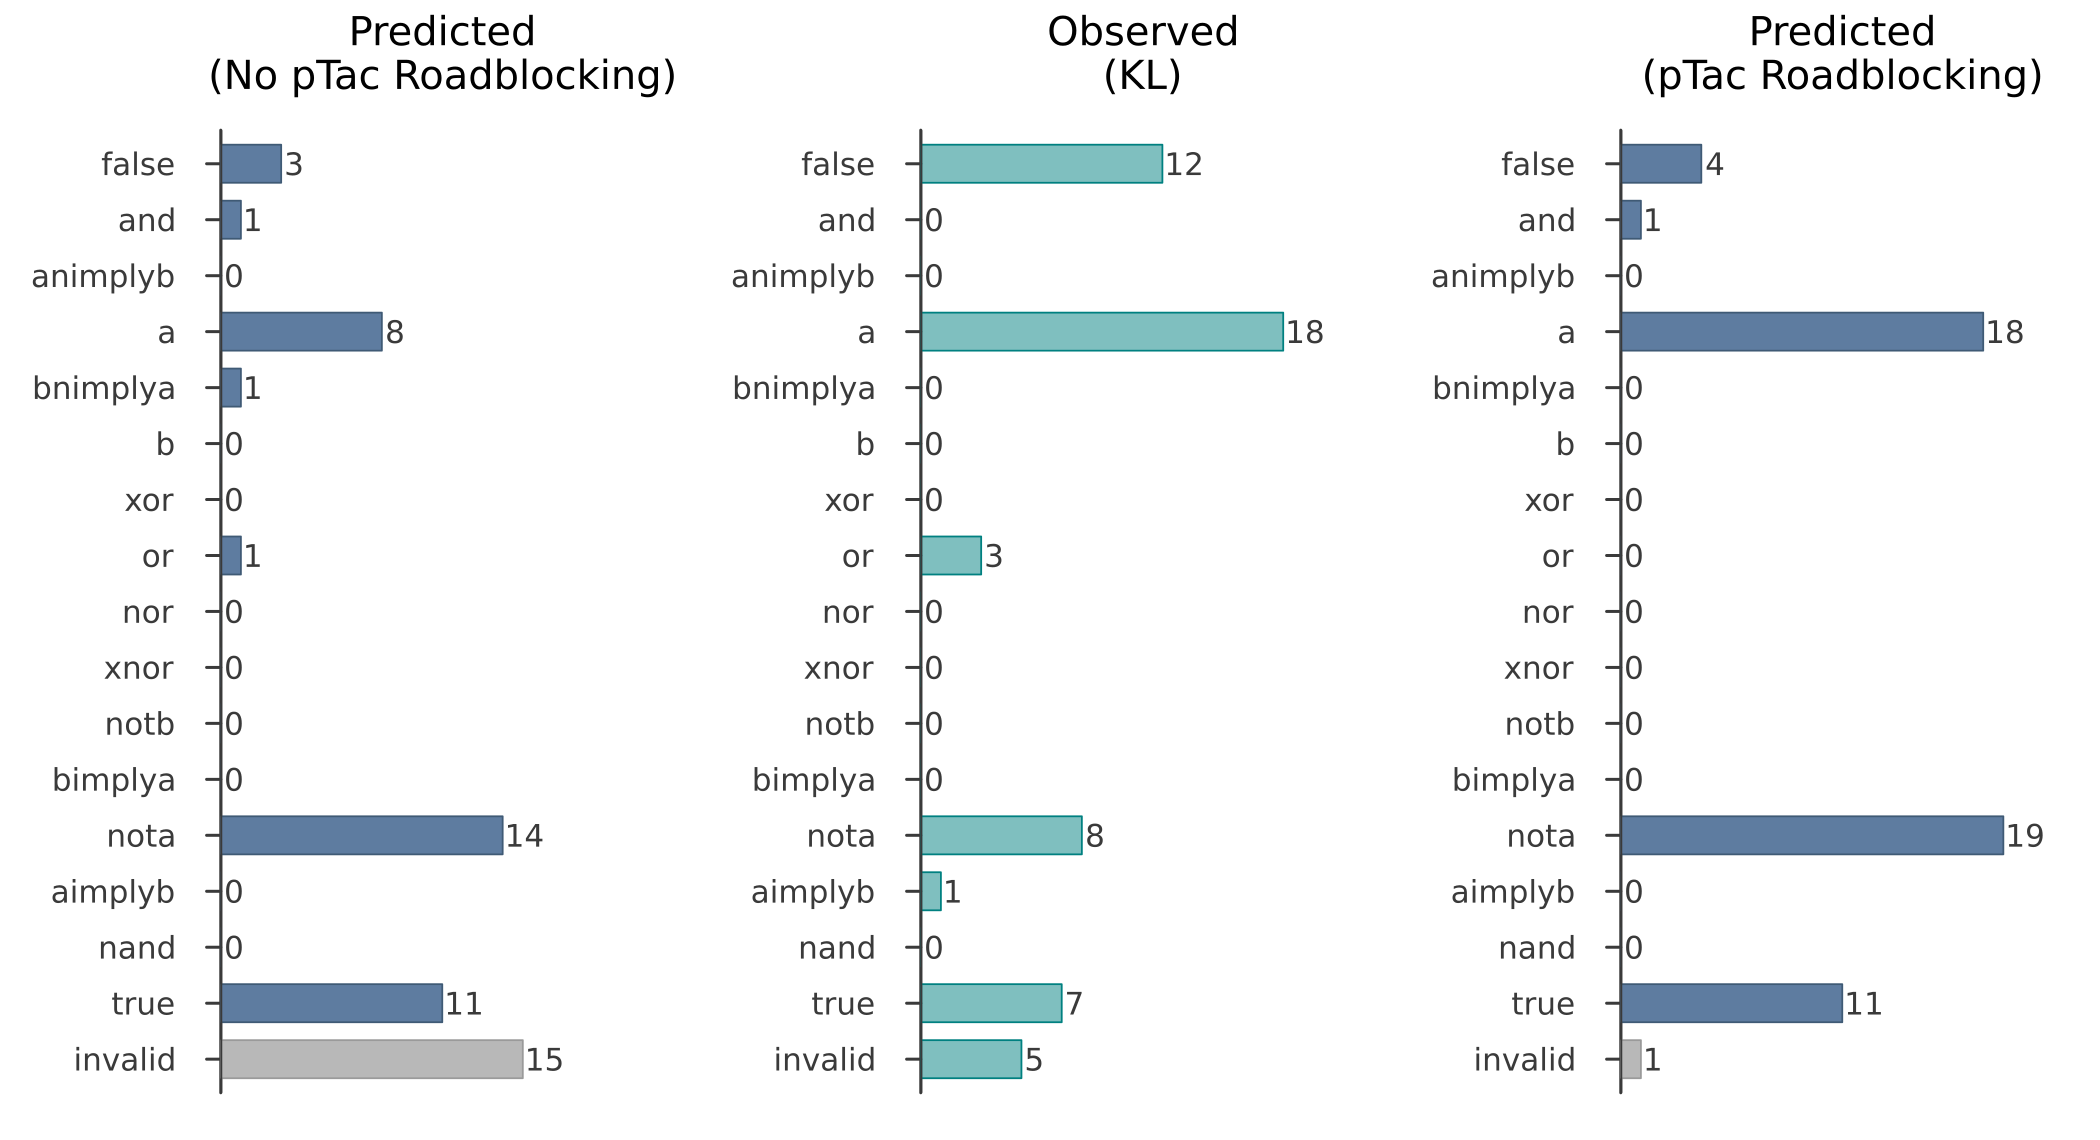

In [7]:
# One shared set of genotypes, so the bar lengths compare like for like. invalid is a
# call on both axes and not a gap, so the flow-invalid circuits stay in every panel
has_observed = .!ismissing.(results.observed)

function tally(calls)
    counts = zeros(Int, length(labels))
    for call in calls
        counts[findfirst(==(Symbol(call)), labels)] += 1
    end
    return counts
end

vs_counts = [tally(results.predicted_disable_Tra[has_observed]),
             tally(skipmissing(results.observed)),
             tally(results.predicted_disable_Tra_roadblock_pTac[has_observed])]

vs_panel = (xlims=(0, maximum(maximum.(vs_counts)) * 1.16),
            titlefontsize=9, tickfontsize=7,
            left_margin=2Plots.mm, right_margin=1Plots.mm,
            top_margin=4Plots.mm, bottom_margin=2Plots.mm)

fig_vs = plot(
    plot_phenotypes(labels, vs_counts[1];
                    title="Predicted\n(No pTac Roadblocking)", vs_panel...),
    plot_phenotypes(labels, vs_counts[2]; title="Observed\n(KL)",
                    fillcolor=:teal, fillalpha=0.5, linecolor=:teal, vs_panel...),
    plot_phenotypes(labels, vs_counts[3];
                    title="Predicted\n(pTac Roadblocking)", vs_panel...);
    layout=(1, 3), size=(700, 380), dpi=300)

savefig(fig_vs, plotsdir("ms_experimental_distributions_kl.png"))
fig_vs

## Divergent Circuits

In [8]:
# every unique genotype, including the ten that are not legal a-b-c-a-b-c assemblies.
# results stays at the 54 valid ones, so no figure and no CSV is affected by this frame.
all_unique = unique(genotypes, :genotype)

accuracy_frame = DataFrame(
    valid = all_unique.valid,
    observed = [get(observed_function, group_of(circuit), missing)
                for circuit in all_unique.circuit],
    predicted_disable_Tra = [predict(parts_of(g), pc_tra) for g in all_unique.circuit_parts],
    predicted_disable_Tra_roadblock_pTac =
        [predict(parts_of(g), pc_tra_rb) for g in all_unique.circuit_parts],
)

# invalid is matched like any other phenotype, so no row is excluded from either denominator
function report_accuracy(prediction)
    hit = [!ismissing(call) && Symbol(call) == p
           for (call, p) in zip(accuracy_frame.observed, prediction)]
    total, valid = count(hit), count(hit .& accuracy_frame.valid)
    n_total, n_valid = length(hit), count(accuracy_frame.valid)
    println("  correct  $total/$n_total unique genotypes "
            * "($(round(100total / n_total, digits=1))%)"
            * "  ·  $valid/$n_valid unique valid "
            * "($(round(100valid / n_valid, digits=1))%)")
end

println("$(nrow(accuracy_frame)) unique genotypes, $(count(accuracy_frame.valid)) of them valid")


64 unique genotypes, 54 of them valid


In [9]:
results.diverges = [!ismissing(call) && Symbol(call) != prediction
                   for (call, prediction) in
                       zip(results.observed, results.predicted_disable_Tra)]

divergent(call) = results[[d && !ismissing(o) && o == call
                           for (d, o) in zip(results.diverges, results.observed)], :]

println("no roadblocking")
println("  $(count(results.diverges)) of $(nrow(results)) circuits diverge")
report_accuracy(accuracy_frame.predicted_disable_Tra)


no roadblocking
  32 of 54 circuits diverge
  correct  25/64 unique genotypes (39.1%)  ·  22/54 unique valid (40.7%)


In [10]:
results.diverges = [!ismissing(call) && Symbol(call) != prediction
                   for (call, prediction) in
                       zip(results.observed, results.predicted_disable_Tra_roadblock_pTac)]

divergent(call) = results[[d && !ismissing(o) && o == call
                           for (d, o) in zip(results.diverges, results.observed)], :]

println("pTac roadblocking")
println("  $(count(results.diverges)) of $(nrow(results)) circuits diverge")
report_accuracy(accuracy_frame.predicted_disable_Tra_roadblock_pTac)


pTac roadblocking
  22 of 54 circuits diverge
  correct  36/64 unique genotypes (56.2%)  ·  32/54 unique valid (59.3%)


In [11]:
divergent("false")

Row,circuit,circuit_parts,observed,predicted_disable_Tra,predicted_disable_Tra_roadblock_pTac,diverges
,String15,String,String7,Symbol,Symbol,Bool
1,circuit_49,pTac-SrpR-pSrpR-pTra-pBAD-Spacer2-AraC-PhlF-pSrpR-pTra-pBAD-BM3R1,false,nota,nota,true
2,circuit_27,pTac-SrpR-Spacer3-pTet-tPhlF-AraC-PhlF-Spacer3-BM3R1,false,invalid,invalid,true
3,circuit_8,pTac-SrpR-Spacer3-BM3R1-pTac-SrpR-pSrpR-pTra-pBAD-BM3R1,false,nota,nota,true
4,circuit_56,pTac-SrpR-pSrpR-pTra-pBAD-BM3R1-pTac-SrpR-pSrpR-pTra-pBAD-BM3R1,false,invalid,nota,true
5,circuit_21,pTac-SrpR-pSrpR-pTra-pBAD-BM3R1-AraC-PhlF-pSrpR-pTra-pBAD-BM3R1,false,nota,nota,true
6,circuit_33,pTac-SrpR-pSrpR-pTra-Spacer2-AraC-PhlF-Spacer3-BM3R1,false,nota,nota,true
7,circuit_34,AraC-PhlF-pSrpR-pTra-BM3R1-AraC-PhlF-pSrpR-pTra-Spacer1,false,true,true,true
8,circuit_82,AraC-PhlF-Spacer3-Spacer2-AraC-PhlF-pSrpR-pTra-pBAD-Spacer1,false,true,true,true


In [12]:
divergent("a")

Row,circuit,circuit_parts,observed,predicted_disable_Tra,predicted_disable_Tra_roadblock_pTac,diverges
,String15,String,String7,Symbol,Symbol,Bool
1,circuit_45,pTac-SrpR-pSrpR-pTra-pBAD-Spacer1-AraC-PhlF-pSrpR-pTra-pBAD-BM3R1,a,nota,nota,true
2,circuit_57,pTac-SrpR-Spacer3-BM3R1-AraC-PhlF-pSrpR-pTra-pBAD-Spacer2,a,true,true,true


In [13]:
divergent("or")

Row,circuit,circuit_parts,observed,predicted_disable_Tra,predicted_disable_Tra_roadblock_pTac,diverges
,String15,String,String7,Symbol,Symbol,Bool
1,circuit_75,AraC-PhlF-Spacer3-pTet-tPhlF-pTac-SrpR-Spacer3-BM3R1,or,or,a,true
2,circuit_42,pTac-SrpR-Spacer3-BM3R1-pTac-SrpR-Spacer3-TraRW,or,a,a,true
3,circuit_54,pTac-SrpR-pSrpR-pTra-Spacer2-AraC-PhlF-pSrpR-pTra-pBAD-pTet-tPhlF,or,and,and,true


In [14]:
divergent("nota")

Row,circuit,circuit_parts,observed,predicted_disable_Tra,predicted_disable_Tra_roadblock_pTac,diverges
,String15,String,String7,Symbol,Symbol,Bool
1,circuit_29,AraC-PhlF-pSrpR-pTra-BM3R1-AraC-PhlF-pSrpR-pTra-pBAD-Spacer2,nota,true,true,true


In [15]:
divergent("aimplyb")

Row,circuit,circuit_parts,observed,predicted_disable_Tra,predicted_disable_Tra_roadblock_pTac,diverges
,String15,String,String7,Symbol,Symbol,Bool
1,circuit_2,AraC-PhlF-pSrpR-pTra-Spacer2-pTac-SrpR-pSrpR-pTra-BM3R1,aimplyb,invalid,nota,true


In [16]:
divergent("nand")

Row,circuit,circuit_parts,observed,predicted_disable_Tra,predicted_disable_Tra_roadblock_pTac,diverges
,String15,String,String7,Symbol,Symbol,Bool


In [17]:
divergent("true")

Row,circuit,circuit_parts,observed,predicted_disable_Tra,predicted_disable_Tra_roadblock_pTac,diverges
,String15,String,String7,Symbol,Symbol,Bool
1,circuit_28,pTac-SrpR-pSrpR-pTra-BM3R1-AraC-PhlF-pSrpR-pTra-Spacer2,true,nota,nota,true
2,circuit_23,pTac-SrpR-pSrpR-pTra-Spacer1-AraC-PhlF-pSrpR-pTra-BM3R1,true,nota,nota,true


In [18]:
CSV.write(datadir("ms_experimental_predictions_kl.csv"), results);